In [1]:
import numpy as np
import pandas as pd
import os
import sys
import time
import gc
import scipy as sp
import collections
import scipy
from collections import Counter

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import matplotlib as mpl
import matplotlib.pylab as plb

#########################################
import sklearn as sk
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import pairwise_distances
import sklearn.manifold
import sklearn.manifold
print(sklearn.__version__)
np.set_printoptions(threshold=sys.maxsize)

# import warnings filter
from warnings import simplefilter
# ignore all future warnings
simplefilter(action='ignore', category=FutureWarning)

#########################################
import pickle
import shutil
import os.path

from cell2mol.tmcharge_common import Cell, atom, molecule, ligand, metal
from cell2mol.elementdata import ElementData 
from cell2mol.tmcharge_common import getradii, getconec, get_adjacency_types, labels2formula 

1.4.0


In [2]:
scopepath = '/Users/sergivela/Documents/SCOPE/Program/'
sys.path.append(scopepath)

import Scope 
from Scope import *

In [3]:
#############################
### Loads Rdkit & xyz2mol ###
#############################

from rdkit import Chem
from rdkit.Chem import Scaffolds
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem import Draw
from rdkit.Chem.Draw.MolDrawing import DrawingOptions  # Only needed if modifying defaults
DrawingOptions.bondLineWidth = 2.2

# IPythonConsole.ipython_useSVG = False
from rdkit import rdBase
if "ipykernel" in sys.modules:
    try:
        from rdkit.Chem.Draw import IPythonConsole
    except ModuleNotFoundError:
        pass
# print("RDKIT Version:", rdBase.rdkitVersion)
rdBase.DisableLog("rdApp.*")

In [4]:
import mols2grid

In [5]:
unique_ligands = "/Users/sergivela/Documents/SCOPE/Database_SCO/7-Ligands/unique_ligands.npy"

if os.path.isfile(unique_ligands):
    ligs = np.load(unique_ligands, allow_pickle=True)
    print(len(ligs),"unique ligands found")


## Was 549 ligands

556 unique ligands found


In [9]:
new_binary_folder = "/Users/sergivela/Documents/SCOPE/Database_SCO/7-Ligands/Unique_Ligands_Binaries/"
new_calcs_folder  = "/Users/sergivela/Documents/SCOPE/Database_SCO/7-Ligands/Unique_Ligands_Binaries/1-Optimizations/"

In [14]:
ligs[0]

------------- SCOPE LIGAND Object --------------
 Version               = 2.0
 Type                  = specie
 Sub-Type              = ligand
 Number of Atoms       = 3
 Formula               = C-N-S
 Has Adjacency Matrix  = YES
 Number of Parents     = 2
 Total Charge          = -1
 SMILES                = [H][N-]C#[S+]
 # HAS RDKIT OBJECT    = YES
------------------------------------------------

In [15]:
from Scope.Classes_Molecule import import_molecule

for idx, ulig in enumerate(ligs):
    new_binary_path = new_binary_folder+"Ulig_"+str(idx)+".npy" 
    imp = import_molecule(ulig)
    sys = gmol2sys(imp, "LS", "Ulig_"+str(idx))
    sys.save(new_binary_path)

SAVING Molecule object to /Users/sergivela/Documents/SCOPE/Database_SCO/7-Ligands/Unique_Ligands_Binaries/Ulig_0.npy
SAVING Molecule object to /Users/sergivela/Documents/SCOPE/Database_SCO/7-Ligands/Unique_Ligands_Binaries/Ulig_1.npy
SAVING Molecule object to /Users/sergivela/Documents/SCOPE/Database_SCO/7-Ligands/Unique_Ligands_Binaries/Ulig_2.npy
SAVING Molecule object to /Users/sergivela/Documents/SCOPE/Database_SCO/7-Ligands/Unique_Ligands_Binaries/Ulig_3.npy
SAVING Molecule object to /Users/sergivela/Documents/SCOPE/Database_SCO/7-Ligands/Unique_Ligands_Binaries/Ulig_4.npy
SAVING Molecule object to /Users/sergivela/Documents/SCOPE/Database_SCO/7-Ligands/Unique_Ligands_Binaries/Ulig_5.npy
SAVING Molecule object to /Users/sergivela/Documents/SCOPE/Database_SCO/7-Ligands/Unique_Ligands_Binaries/Ulig_6.npy
SAVING Molecule object to /Users/sergivela/Documents/SCOPE/Database_SCO/7-Ligands/Unique_Ligands_Binaries/Ulig_7.npy
SAVING Molecule object to /Users/sergivela/Documents/SCOPE/Datab

## Old Murcko Scaffold Analysis

In [ ]:
mks = []
lig_objects = []
for idx, lig in enumerate(ligs):
    mk = Scaffolds.MurckoScaffold.GetScaffoldForMol(lig.rdkit_obj)
    mks.append(mk)
    lig_objects.append(lig.rdkit_obj)
print(len(ligs), "unique ligands")
print(len(mks), "murcko scaffolds")

549 unique ligands
549 murcko scaffolds


In [ ]:
mols2grid.display(lig_objects)

MolGridWidget()

In [ ]:
mols2grid.display(mks)

MolGridWidget()

### Unique Murcko Generation

In [ ]:
skiplist = []
duplicate_murcko = []
unique_murcko = []
for idx, mk1 in enumerate(mks):
    if idx not in skiplist:
        unique_murcko.append(mk1)
        for jdx, mk2 in enumerate(mks):
            if jdx > idx and jdx not in skiplist:
                if Chem.MolToSmiles(mk1) == Chem.MolToSmiles(mk2): 
                    issame = True
                    #print(Chem.MolToSmiles(mks[1], "is duplicate")
                else: 
                    issame = False
                if issame:
                    skiplist.append(jdx)
                    duplicate_murcko.append([mk1, mk2])

In [ ]:
unique_murcko_ids = []
for idx, mk in enumerate(mks):
    for jdx, umk in enumerate(unique_murcko):
        #print(Chem.MolToSmiles(mk), Chem.MolToSmiles(umk))
        if Chem.MolToSmiles(mk) == Chem.MolToSmiles(umk):
            unique_murcko_ids.append(jdx)

In [ ]:
save_binary(mks,"/Users/sergivela/Documents/SCOPE/Database_SCO/7-Ligands/murcko_scaffolds.npy")
save_binary(unique_murcko,"/Users/sergivela/Documents/SCOPE/Database_SCO/7-Ligands/unique_murcko.npy")
save_binary(unique_murcko_ids, "/Users/sergivela/Documents/SCOPE/Database_SCO/7-Ligands/unique_murcko_id.npy")

## Remap Old Ligand Computations

In [6]:
old_binary_folder = "/Users/sergivela/Documents/SCOPE/Database_SCO/7-Ligands/Older/Unique_Ligands/"
old_calcs_folder  = "/Users/sergivela/Documents/SCOPE/Database_SCO/7-Ligands/Older/Unique_Ligands/Optimized/" 
new_binary_folder = "/Users/sergivela/Documents/SCOPE/Database_SCO/7-Ligands/Unique_Ligands_Binaries/"
new_calcs_folder  = "/Users/sergivela/Documents/SCOPE/Database_SCO/7-Ligands/Unique_Ligands_Binaries/1-Optimizations/"

In [7]:
old_systems = []
for idx in range(549):
    if not os.path.isfile(old_binary_folder+"Ulig_"+str(idx)+".npy"): print("merda", idx); pass
    osys = load_binary(old_binary_folder+"Ulig_"+str(idx)+".npy")    
    old_systems.append(osys)
print(len(old_systems), "old ligand files loaded")

549 old ligand files loaded


In [ ]:
from Scope.Classes_Molecule import import_molecule

map = []
skiplist = []
for idx, ulig in enumerate(ligs):
    found = False
    for jdx, olig in enumerate(old_systems):
        if not found and jdx not in skiplist:
            issame = compare_species(ulig, olig)
            if issame:
                skiplist.append(jdx)
                map.append(tuple([idx, jdx]))
                found = True

                if idx == 2: print(idx, jdx)
                ## Copies binary
                old_binary_path = old_binary_folder+"Ulig_"+str(jdx)+".npy" 
                new_binary_path = new_binary_folder+"Ulig_"+str(idx)+".npy" 
                if os.path.isfile(old_binary_path) and not os.path.isfile(new_binary_path):
                    imp = import_molecule(olig)
                    sys = gmol2sys(imp, "LS", "Ulig_"+str(idx))
                    sys.save(new_binary_path)
                    #shutil.copy(old_binary_path, new_binary_path)
 
                ## Copies Computations
                for i in range(10):
                    for ext in list(["com", "log", "sub"]):
                        old_calc_path = f"{old_calcs_folder}Ulig_{jdx}_opt_r{i}_LS.{ext}"
                        new_calc_path = f"{new_calcs_folder}Ulig_{idx}_opt_r{i}_LS.{ext}"
                        if os.path.isfile(old_calc_path) and not os.path.isfile(new_calc_path):
                            if idx == 2: print(old_calc_path, new_calc_path)
                            shutil.copy(old_calc_path, new_calc_path)

    if not found: 
        print(idx, ulig.formula, ulig.get_parent("cell").refcode, "not found")                
        dst = new_binary_folder+"Ulig_"+str(idx)+".npy"
        save_binary(ulig, dst)

AttributeError: 'ligand' object has no attribute 'set_element_count'

In [ ]:
sys = load_binary("/Users/sergivela/Documents/SCOPE/Database_SCO/7-Ligands/Unique_Ligands_Binaries/Ulig_2.npy")

In [ ]:
sys

------------- SCOPE MOLECULE Object --------------
 Version               = 2.0
 Type                  = specie
 Sub-Type              = molecule
 Number of Atoms       = 26
 Formula               = H11-C11-N3-O
 Has Adjacency Matrix  = YES
 Number of Parents     = 0
 Total Charge          = 0
 Spin                  = LS
 SMILES                = [H]C(=Nc1c([H])c([H])c(OC([H])([H])[H])c([H])c1[H])c1nc([H])c([H])n1[H]
------------------------------------------------

In [ ]:
map

[(0, 0),
 (1, 1),
 (2, 2),
 (3, 3),
 (4, 4),
 (5, 5),
 (6, 6),
 (7, 7),
 (8, 8),
 (9, 9),
 (10, 10),
 (11, 11),
 (12, 12),
 (13, 13),
 (14, 14),
 (15, 15),
 (16, 16),
 (17, 17),
 (18, 18),
 (19, 19),
 (20, 20),
 (21, 21),
 (22, 22),
 (23, 23),
 (24, 24),
 (25, 25),
 (26, 26),
 (27, 27),
 (28, 28),
 (29, 29),
 (30, 30),
 (31, 31),
 (32, 32),
 (33, 33),
 (34, 34),
 (35, 35),
 (36, 36),
 (37, 37),
 (38, 38),
 (39, 39),
 (40, 40),
 (41, 41),
 (42, 42),
 (43, 43),
 (44, 44),
 (45, 45),
 (46, 46),
 (47, 47),
 (48, 48),
 (49, 49),
 (50, 50),
 (51, 51),
 (52, 52),
 (53, 53),
 (54, 54),
 (55, 55),
 (56, 56),
 (57, 57),
 (58, 58),
 (59, 59),
 (60, 60),
 (61, 61),
 (62, 62),
 (63, 63),
 (64, 64),
 (65, 65),
 (66, 66),
 (67, 67),
 (68, 68),
 (69, 69),
 (70, 70),
 (71, 71),
 (72, 72),
 (73, 73),
 (74, 74),
 (75, 75),
 (76, 76),
 (77, 77),
 (78, 78),
 (79, 79),
 (80, 80),
 (81, 81),
 (82, 82),
 (83, 83),
 (84, 84),
 (85, 85),
 (86, 86),
 (87, 87),
 (88, 88),
 (89, 89),
 (90, 90),
 (91, 91),
 (92, 92

In [ ]:
for t in map:
    ## I don't want to copy old binary. I prefer to create a new one, so I comment shutil part
    #if os.path.isfile(old_binary_folder+"Ulig_"+str(t[1])+".npy"): 
    #    src = old_binary_folder+"Ulig_"+str(t[1])+".npy"
    dst = new_binary_folder+"Ulig_"+str(t[0])+".npy"
    #    print("copy:")
    #    print("    src:", src)
    #    print("    dst:", dst)
    #    #shutil.copy(src,dst)
    save_binary(ligs[t[0]], dst)
    for r in range(10):
        if os.path.isfile(old_calcs_folder+"Ulig_"+str(t[1])+"_opt_r"+str(r)+"_LS.com"): 
            src = old_calcs_folder+"Ulig_"+str(t[1])+"_opt_r"+str(r)+"_LS.com" 
            dst = new_calcs_folder+"Ulig_"+str(t[0])+"_opt_r"+str(r)+"_LS.com"
            if not os.path.isfile(dst): shutil.copy(src,dst)
        if os.path.isfile(old_calcs_folder+"Ulig_"+str(t[1])+"_opt_r"+str(r)+"_LS.log"): 
            src = old_calcs_folder+"Ulig_"+str(t[1])+"_opt_r"+str(r)+"_LS.log" 
            dst = new_calcs_folder+"Ulig_"+str(t[0])+"_opt_r"+str(r)+"_LS.log"
            if not os.path.isfile(dst): shutil.copy(src,dst)
        if os.path.isfile(old_calcs_folder+"Ulig_"+str(t[1])+"_opt_r"+str(r)+"_LS.sub"): 
            src = old_calcs_folder+"Ulig_"+str(t[1])+"_opt_r"+str(r)+"_LS.sub" 
            dst = new_calcs_folder+"Ulig_"+str(t[0])+"_opt_r"+str(r)+"_LS.sub"
            if not os.path.isfile(dst): shutil.copy(src,dst)

In [ ]:
ligs[135]

------------- SCOPE LIGAND Object --------------
 Version               = 2.0
 Type                  = specie
 Sub-Type              = ligand
 Number of Atoms       = 56
 Formula               = H22-B-C27-N6
 Has Adjacency Matrix  = YES
 Number of Parents     = 2
 Total Charge          = -1
 SMILES                = [H]c1c([H])c([H])c(-c2nn([B-]([H])(n3nc(-c4c([H])c([H])c([H])c([H])c4[H])c([H])c3[H])n3nc(-c4c([H])c([H])c([H])c([H])c4[H])c([H])c3[H])c([H])c2[H])c([H])c1[H]
 # HAS RDKIT OBJECT    = YES
------------------------------------------------

In [ ]:
ligs[425]

------------- SCOPE LIGAND Object --------------
 Version               = 2.0
 Type                  = specie
 Sub-Type              = ligand
 Number of Atoms       = 51
 Formula               = H8-C25-N6-O2-F10
 Has Adjacency Matrix  = YES
 Number of Parents     = 2
 Total Charge          = 0
 SMILES                = [H]c1nc(N(c2nc(Oc3c(F)c(F)c(F)c(F)c3F)nc(Oc3c(F)c(F)c(F)c(F)c3F)n2)c2nc([H])c([H])c([H])c2[H])c([H])c([H])c1[H]
 # HAS RDKIT OBJECT    = YES
------------------------------------------------

## Proves

In [ ]:
from rdkit import DataStructs

matrix = np.zeros((len(unique_murcko), len(unique_murcko)))
for idx, mk1 in enumerate(unique_murcko):
    mp1 = AllChem.GetMorganFingerprint(mk1,2)
    for jdx, mk2 in enumerate(unique_murcko):
        if idx != jdx:
            mp2 = AllChem.GetMorganFingerprint(mk2,2)      
            matrix[idx,jdx] = DataStructs.TanimotoSimilarity(mp1,mp2)
        else:
            matrix[idx,jdx] = 1.0

In [ ]:
eigenval, eigenvec = np.linalg.eig(matrix)

In [ ]:
# from rdkit.ML.Descriptors.MoleculeDescriptors import MolecularDescriptorCalculator

# chosen_descriptors1 = ['BalabanJ', 'BertzCT', 'Chi0', 'Chi0n', 'Chi0v', 'Chi1', 'Chi1n', 'Chi1v', 'Chi2n', 'Chi2v', 'Chi3n', 'Chi3v', 'Chi4n', 'Chi4v', 'EState_VSA1', 'EState_VSA10', 'EState_VSA11', 'EState_VSA2', 'EState_VSA3', 'EState_VSA4', 'EState_VSA5', 'EState_VSA6', 'EState_VSA7', 'EState_VSA8', 'EState_VSA9', 'ExactMolWt', 'FpDensityMorgan1', 'FpDensityMorgan2', 'FpDensityMorgan3', 'FractionCSP3', 'HallKierAlpha', 'HeavyAtomCount', 'HeavyAtomMolWt', 'Ipc', 'Kappa1', 'Kappa2', 'Kappa3', 'LabuteASA', 'MaxAbsEStateIndex', 'MaxAbsPartialCharge', 'MaxEStateIndex', 'MaxPartialCharge', 'MinAbsEStateIndex', 'MinAbsPartialCharge', 'MinEStateIndex', 'MinPartialCharge', 'MolLogP', 'MolMR', 'MolWt', 'NHOHCount', 'NOCount', 'NumAliphaticCarbocycles', 'NumAliphaticHeterocycles', 'NumAliphaticRings', 'NumAromaticCarbocycles', 'NumAromaticHeterocycles', 'NumAromaticRings', 'NumHAcceptors', 'NumHDonors', 'NumHeteroatoms', 'NumRadicalElectrons', 'NumRotatableBonds', 'NumSaturatedCarbocycles', 'NumSaturatedHeterocycles', 'NumSaturatedRings', 'NumValenceElectrons', 'PEOE_VSA1', 'PEOE_VSA10', 'PEOE_VSA11', 'PEOE_VSA12', 'PEOE_VSA13', 'PEOE_VSA14', 'PEOE_VSA2', 'PEOE_VSA3', 'PEOE_VSA4', 'PEOE_VSA5', 'PEOE_VSA6', 'PEOE_VSA7', 'PEOE_VSA8', 'PEOE_VSA9', 'RingCount', 'SMR_VSA1', 'SMR_VSA10', 'SMR_VSA2', 'SMR_VSA3', 'SMR_VSA4', 'SMR_VSA5', 'SMR_VSA6', 'SMR_VSA7', 'SMR_VSA8', 'SMR_VSA9', 'SlogP_VSA1', 'SlogP_VSA10', 'SlogP_VSA11', 'SlogP_VSA12', 'SlogP_VSA2', 'SlogP_VSA3', 'SlogP_VSA4', 'SlogP_VSA5', 'SlogP_VSA6', 'SlogP_VSA7', 'SlogP_VSA8', 'SlogP_VSA9', 'TPSA', 'VSA_EState1', 'VSA_EState10', 'VSA_EState2', 'VSA_EState3', 'VSA_EState4', 'VSA_EState5', 'VSA_EState6', 'VSA_EState7', 'VSA_EState8', 'VSA_EState9', 'fr_Al_COO', 'fr_Al_OH', 'fr_Al_OH_noTert', 'fr_ArN', 'fr_Ar_COO', 'fr_Ar_N', 'fr_Ar_NH', 'fr_Ar_OH', 'fr_COO', 'fr_COO2', 'fr_C_O', 'fr_C_O_noCOO', 'fr_C_S', 'fr_HOCCN', 'fr_Imine', 'fr_NH0', 'fr_NH1', 'fr_NH2', 'fr_N_O', 'fr_Ndealkylation1', 'fr_Ndealkylation2', 'fr_Nhpyrrole', 'fr_SH', 'fr_aldehyde', 'fr_alkyl_carbamate', 'fr_alkyl_halide', 'fr_allylic_oxid', 'fr_amide', 'fr_amidine', 'fr_aniline', 'fr_aryl_methyl', 'fr_azide', 'fr_azo', 'fr_barbitur', 'fr_benzene', 'fr_benzodiazepine', 'fr_bicyclic', 'fr_diazo', 'fr_dihydropyridine', 'fr_epoxide', 'fr_ester', 'fr_ether', 'fr_furan', 'fr_guanido', 'fr_halogen', 'fr_hdrzine', 'fr_hdrzone', 'fr_imidazole', 'fr_imide', 'fr_isocyan', 'fr_isothiocyan', 'fr_ketone', 'fr_ketone_Topliss', 'fr_lactam', 'fr_lactone', 'fr_methoxy', 'fr_morpholine', 'fr_nitrile', 'fr_nitro', 'fr_nitro_arom', 'fr_nitro_arom_nonortho', 'fr_nitroso', 'fr_oxazole', 'fr_oxime', 'fr_para_hydroxylation', 'fr_phenol', 'fr_phenol_noOrthoHbond', 'fr_phos_acid', 'fr_phos_ester', 'fr_piperdine', 'fr_piperzine', 'fr_priamide', 'fr_prisulfonamd', 'fr_pyridine', 'fr_quatN', 'fr_sulfide', 'fr_sulfonamd', 'fr_sulfone', 'fr_term_acetylene', 'fr_tetrazole', 'fr_thiazole', 'fr_thiocyan', 'fr_thiophene', 'fr_unbrch_alkane', 'fr_urea', 'qed']
# chosen_descriptors2 = ['MaxEStateIndex', 'MinEStateIndex', 'MaxAbsEStateIndex', 'MinAbsEStateIndex', 'qed', 'MolWt', 'HeavyAtomMolWt', 'ExactMolWt', 'NumValenceElectrons', 'NumRadicalElectrons', 'MaxPartialCharge', 'MinPartialCharge', 'MaxAbsPartialCharge', 'MinAbsPartialCharge', 'FpDensityMorgan1', 'FpDensityMorgan2', 'FpDensityMorgan3', 'BalabanJ', 'BertzCT', 'Chi0', 'Chi0n', 'Chi0v', 'Chi1', 'Chi1n', 'Chi1v', 'Chi2n', 'Chi2v', 'Chi3n', 'Chi3v', 'Chi4n', 'Chi4v', 'HallKierAlpha', 'Ipc', 'Kappa1', 'Kappa2', 'Kappa3', 'LabuteASA', 'PEOE_VSA1', 'PEOE_VSA10', 'PEOE_VSA11', 'PEOE_VSA12', 'PEOE_VSA13', 'PEOE_VSA14', 'PEOE_VSA2', 'PEOE_VSA3', 'PEOE_VSA4', 'PEOE_VSA5', 'PEOE_VSA6', 'PEOE_VSA7', 'PEOE_VSA8', 'PEOE_VSA9', 'SMR_VSA1', 'SMR_VSA10', 'SMR_VSA2', 'SMR_VSA3', 'SMR_VSA4', 'SMR_VSA5', 'SMR_VSA6', 'SMR_VSA7', 'SMR_VSA8', 'SMR_VSA9', 'SlogP_VSA1', 'SlogP_VSA10', 'SlogP_VSA11', 'SlogP_VSA12', 'SlogP_VSA2', 'SlogP_VSA3', 'SlogP_VSA4', 'SlogP_VSA5', 'SlogP_VSA6', 'SlogP_VSA7', 'SlogP_VSA8', 'SlogP_VSA9', 'TPSA', 'EState_VSA1', 'EState_VSA10', 'EState_VSA11', 'EState_VSA2', 'EState_VSA3', 'EState_VSA4', 'EState_VSA5', 'EState_VSA6', 'EState_VSA7', 'EState_VSA8', 'EState_VSA9', 'VSA_EState1', 'VSA_EState10', 'VSA_EState2', 'VSA_EState3', 'VSA_EState4', 'VSA_EState5', 'VSA_EState6', 'VSA_EState7', 'VSA_EState8', 'VSA_EState9', 'FractionCSP3', 'HeavyAtomCount', 'NHOHCount', 'NOCount', 'NumAliphaticCarbocycles', 'NumAliphaticHeterocycles', 'NumAliphaticRings', 'NumAromaticCarbocycles', 'NumAromaticHeterocycles', 'NumAromaticRings', 'NumHAcceptors', 'NumHDonors', 'NumHeteroatoms', 'NumRotatableBonds', 'NumSaturatedCarbocycles', 'NumSaturatedHeterocycles', 'NumSaturatedRings', 'RingCount', 'MolLogP', 'MolMR']
# mol_descriptor_calculator1 = MolecularDescriptorCalculator(chosen_descriptors1)
# mol_descriptor_calculator2 = MolecularDescriptorCalculator(chosen_descriptors2)

# #     worked1 = False
# #     try:
# #         dA1 = list(mol_descriptor_calculator1.CalcDescriptors(mk1))
# #         dB1 = list(mol_descriptor_calculator2.CalcDescriptors(mk1))
# #         worked1 = True
# #     except: pass
    

In [ ]:
from rdkit import DataStructs

arrays = []
for idx, mk1 in enumerate(unique_murcko):
    bi = {}
    fp = AllChem.GetMorganFingerprintAsBitVect(mk1,2,nBits=2048,bitInfo=bi)
    fp_arr = np.zeros((1,))
    DataStructs.ConvertToNumpyArray(fp,fp_arr)
    arrays.append(fp_arr)

In [ ]:
from sklearn.decomposition import PCA

pca_job = PCA(n_components=1)
pca = pca_job.fit_transform(arrays)

for idx, val1 in enumerate(pca):
    for jdx, val2 in enumerate(pca):
        if idx == jdx: tani = 1.0
        else: tani = DataStructs.TanimotoSimilarity(AllChem.GetMorganFingerprint(unique_murcko[idx],2),AllChem.GetMorganFingerprint(unique_murcko[jdx],2))
        #print(idx, jdx, np.abs(val1-val2), np.abs(1-tani))
        


In [ ]:
save_binary(pca, "/Users/sergivela/Documents/SCOPE/Database_SCO/7-Unique_Ligands/pca_n1.npy")

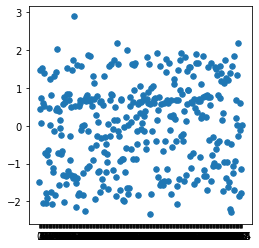

In [ ]:
xplot = [str(i) for i in range(0, len(pca))]
yplot = pca

fig, axs = plt.subplots(figsize=[4,4])
axs.scatter(xplot, yplot,s=30)

In [ ]:
ext_pca_n1 = []
for idx in unique_murcko_ids:
    ext_pca_n1.append(pca[idx])
                          
print(len(ext_pca_n1))

559


In [ ]:
# sorted(ext_pca_n1)

# st_unique_murcko_ids, st_ext_pca_n1 = zip(*sorted(zip(unique_murcko_ids, ext_pca_n1),
# key=operator.itemgetter(1), reverse=True))

together = zip(ext_pca_n1, st_unique_murcko_ids)
sorted_together =  sorted(together)

st_unique_murcko_ids = [x[1] for x in sorted_together]
st_ext_pca_n1 = [x[0] for x in sorted_together]

In [ ]:
save_binary(st_unique_murcko_ids, "/Users/sergivela/Documents/SCOPE/Database_SCO/7-Unique_Ligands/st_unique_murcko_ids.npy")
save_binary(st_ext_pca_n1, "/Users/sergivela/Documents/SCOPE/Database_SCO/7-Unique_Ligands/st_ext_pca_n1.npy")

In [ ]:
mols2grid.display(unique_murcko[0:5])

MolGridWidget()

In [ ]:
# TSNE OF LOCAL SLATMS
tsnes = []

for idx, pval in enumerate(perplexities): 
    sk_tsne = sk.manifold.TSNE(perplexity=pval, n_jobs=-1)
    tsne = sk_tsne.fit_transform(pcas[idx])
    tsnes.append(tsne)

In [ ]:
def setlimits(data):
    if np.min(data) > 0: xleft = np.min(data)*0.9
    if np.min(data) <= 0: xleft = np.min(data)*1.1
    xright = np.max(data)*1.1
    if np.min(data) > 0: yleft = np.min(data)*0.9
    if np.min(data) <= 0: yleft = np.min(data)*1.1
    yright = np.max(data)*1.1   
    return xleft, xright, yleft, yright

def getList(dict):
    list = []
    for key in dict.keys():
        list.append(int(key))
    return list

def filter_tsne_data(data, perplexity, properties, targetproperty, filterprop: list=[], filterval: int=0):
    if targetproperty[0] < 0:
        print("non-valid property ID")
        return   
    
    prop = int(targetproperty[0])
    if prop == 0:
        prop_name = "Natoms"
        cmap = 'rainbow'
    
    print("prop_name:", prop_name)
    isfiltering = False
    if len(filterprop) > 0:
        filterprop = int(filterprop[0])
        isfiltering = True

    if prop == 0: 
        xplot = []
        yplot = []
        zplot = []
        for idx, p in enumerate(data):
            if isfiltering:
                if properties[filterprop][idx] == filterval:
                    xplot.append(p[0])
                    yplot.append(p[1])
                    zplot.append(properties[prop][idx])
            else:
                xplot.append(p[0])
                yplot.append(p[1])
                zplot.append(properties[prop][idx])    

    plname = prop_name+"_Perplexity_"+str(perplexity)
    plname = plname.replace("/","_")
        
    return xplot, yplot, zplot, cmap, plname

def plot_tsne(xplot: list, yplot: list, zplot: list, cmap: str, plname: str, xleft: float, xright: float, yleft: float, yright: float):
        ############ DOES PLOT #####################        
        cmap = 'rainbow'
        fig, axs = plt.subplots(figsize=[4,4])
        axs.scatter(xplot, yplot, c=zplot, cmap=cmap, s=30)
        axs.yaxis.set_ticklabels([])
        axs.yaxis.set_ticks([])
        axs.xaxis.set_ticklabels([])
        axs.xaxis.set_ticks([])
        axs.set_xlim(xleft, xright)
        axs.set_ylim(yleft, yright)
#        fig.show()
#         filename=plname
#         if valuelist[jdx] == 50:
#             plt.savefig(os.path.join(figs_dir,filename), dpi=300, bbox_inches='tight')
#             print("Figure saved in:", figs_dir+filename)

In [ ]:

# propertylist = [natoms]

# for idx, data in enumerate(tsnes):
#     # Sets axis limits
#     xleft, xright, yleft, yright = setlimits(data)
#     # Filters data
#     xplot, yplot, zplot, cmap, plname = filter_tsne_data(data, perplexities[idx], propertylist, [0])
#     # Plots
#     plot_tsne(xplot, yplot, zplot, cmap, plname, xleft, xright, yleft, yright)

## AgglomerativeClustering

In [ ]:
import numpy as np

from matplotlib import pyplot as plt
from scipy.cluster.hierarchy import dendrogram
from sklearn.cluster import AgglomerativeClustering

In [ ]:
# def plot_dendrogram(model, **kwargs):
#     # Create linkage matrix and then plot the dendrogram

#     # create the counts of samples under each node
#     counts = np.zeros(model.children_.shape[0])
#     n_samples = len(model.labels_)
#     for i, merge in enumerate(model.children_):
#         current_count = 0
#         for child_idx in merge:
#             if child_idx < n_samples:
#                 current_count += 1  # leaf node
#             else:
#                 current_count += counts[child_idx - n_samples]
#         counts[i] = current_count

#     linkage_matrix = np.column_stack([model.children_, model.distances_, counts]).astype(float)

#     # Plot the corresponding dendrogram
#     dendrogram(linkage_matrix, **kwargs, get_leaves=True, show_leaf_counts=True)

In [ ]:
skiplist = []
duplicate_murcko = []
unique_murcko = []
for idx, mk1 in enumerate(mks):
    if idx not in skiplist:
        murcko_ID = idx
        unique_murcko.append(mk1)
        for jdx, mk2 in enumerate(mks):
            if jdx > idx and jdx not in skiplist:
                if Chem.MolToSmiles(mk1) == Chem.MolToSmiles(mk2): 
                    issame = True
                    #print(Chem.MolToSmiles(mks[1], "is duplicate")
                else: 
                    issame = False
                if issame:
                    skiplist.append(jdx)
                    duplicate_murcko.append([mk1, mk2])

In [ ]:
from rdkit import DataStructs

matrix = np.zeros((len(unique_murcko), len(unique_murcko)))
for idx, mk1 in enumerate(unique_murcko):
    mp1 = AllChem.GetMorganFingerprint(mk1,2)
    for jdx, mk2 in enumerate(unique_murcko):
        if idx != jdx:
            if mk1.GetNumAtoms() > 0 and mk2.GetNumAtoms() > 0:
            #print("Atoms", jdx, mk2.GetNumAtoms())
                mp2 = AllChem.GetMorganFingerprint(mk2,2)      
                matrix[idx,jdx] = DataStructs.TanimotoSimilarity(mp1,mp2)
                matrix[jdx,idx] = DataStructs.TanimotoSimilarity(mp1,mp2)
            else: 
                matrix[idx,jdx] = 0.0
                matrix[jdx,idx] = 0.0
        else:
            matrix[idx,jdx] = 1.0
            matrix[jdx,idx] = 1.0
            
matrix_inverse = np.zeros((len(unique_murcko), len(unique_murcko)))
for idx, row in enumerate(matrix):
    for jdx, value in enumerate(row):
        val_corr = 1 - value
        matrix_inverse[idx,jdx] = val_corr            

natoms = []
murcko_smiles = []
for umk in unique_murcko:
    natoms.append(umk.GetNumAtoms())
    murcko_smiles.append(Chem.MolToSmiles(umk))

346 559 unique murcko and unique ligands found
N_Clusters 346
346 nsamples found


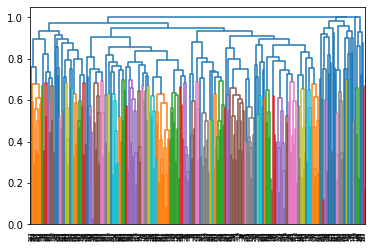

In [ ]:
import scipy.cluster.hierarchy as sch

print(len(unique_murcko), len(ligs), "unique murcko and unique ligands found")
# numleaf = 100

# np.random.seed(1)
#labels=murcko_smiles
labels=[str(i) for i in range(0, len(murcko_smiles))]

# x = np.random.rand(numleaf)
# D = np.zeros([numleaf,numleaf])
# for i in range(numleaf):
#     for j in range(numleaf):
#         D[i,j] = abs(x[i] - x[j])
model = AgglomerativeClustering(distance_threshold=0, n_clusters=None, affinity="precomputed", linkage='complete')
model = model.fit(matrix_inverse)
print("N_Clusters", model.n_clusters_)

counts = np.zeros(model.children_.shape[0])
n_samples = len(model.labels_)
print(n_samples, "nsamples found")
for i, merge in enumerate(model.children_):
    current_count = 0
    for child_idx in merge:
        if child_idx < n_samples:
            current_count += 1  # leaf node
        else:
            current_count += counts[child_idx - n_samples]
    counts[i] = current_count

linkage_matrix = np.column_stack([model.children_, model.distances_, counts]).astype(float)

#Y = sch.linkage(matrix, method='complete')
Z2 = sch.dendrogram(linkage_matrix,labels=labels) #,truncate_mode="level", p=4)
#plot_dend(Z2,addlabels=False)

In [ ]:
mols2grid.display(unique_murcko)

NameError: name 'mols2grid' is not defined

In [ ]:
counts

In [ ]:
model.labels_

array([255, 341, 277, 276, 270, 338, 295, 216, 336, 195, 235, 179, 294,
       233, 191, 273, 272, 243, 248, 316, 214, 325, 288, 177, 203, 224,
       178, 296, 289, 291, 286, 283, 207, 184, 193, 176, 301, 327, 198,
       189, 307, 290, 323, 340, 299, 219, 319, 303, 254, 302, 196, 252,
       247, 345, 284, 197, 309, 194, 199, 258, 180, 250, 267, 329, 271,
       306, 236, 332, 334, 298, 330, 221, 292, 279, 229, 305, 232, 326,
       241, 172, 331, 321, 328, 293, 280, 337, 275, 213, 259, 300, 304,
       313, 204, 239, 217, 335, 253, 285, 238, 181, 117, 311, 175, 215,
       222, 211, 200, 274, 312, 110, 202, 185, 126, 206,  89, 339, 212,
       249, 174, 167, 245, 342, 244, 228, 151, 183, 187, 282, 308, 182,
       201, 146, 315, 320,  97, 150, 100, 121, 153, 246, 314, 152, 265,
       209, 192, 163, 168, 162,  83, 223, 147, 144, 169,  88, 164, 141,
       159, 263, 165, 220, 281, 149, 218, 240, 234, 310, 205, 102, 123,
       225, 208, 154, 109, 106, 230,  87, 343, 269, 251, 188, 29

In [ ]:
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.cm as cm
import matplotlib
from matplotlib.lines import Line2D
#import seaborn as sns 
#sns.set_theme()

colormap_list=["nipy_spectral", "terrain","gist_rainbow","CMRmap","coolwarm","gnuplot","gist_stern","brg","rainbow"]

def plot_dend(Z2,fontsize=8,figsize=None, pallete="gist_rainbow", addlabels=True, show=True,sample_classes=None,colorlabels=None,
         colorlabels_legend=None):
    """
    Drawing a radial dendrogram from a scipy dendrogram output.
    Parameters
    ----------
    Z2 : dictionary
        A dictionary returned by scipy.cluster.hierarchy.dendrogram
    addlabels: bool
        A bool to choose if labels are shown.
    fontsize : float
        A float to specify the font size
    figsize : [x, y] array-like
        1D array-like of floats to specify the figure size
    pallete : string
        Matlab colormap name.
    sample_classes : dict
        A dictionary that contains lists of sample subtypes or classes. These classes appear 
        as color labels of each leaf. Colormaps are automatically assigned. Not compatible 
        with options "colorlabels" and "colorlabels_legend".
        e.g., {"color1":["Class1","Class2","Class1","Class3", ....]} 
    colorlabels : dict
        A dictionary to set color labels to leaves. The key is the name of the color label. 
        The value is the list of RGB color codes, each corresponds to the color of a leaf. 
        e.g., {"color1":[[1,0,0,1], ....]}   
    colorlabels_legend : dict
        A nested dictionary to generate the legends of color labels. The key is the name of 
        the color label. The value is a dictionary that has two keys "colors" and "labels". 
        The value of "colors" is the list of RGB color codes, each corresponds to the class of a leaf. 
        e.g., {"color1":{"colors":[[1,0,0,1], ....], "labels":["label1","label2",...]}}   
    
    Returns
    -------
    Raises
    ------
    Notes
    -----
    References
    ----------
    See Also
    --------
    Examples
    --------
    """
    if figsize==None and colorlabels != None:
        figsize=[20,10]
    elif figsize==None and sample_classes != None:
        figsize=[20,10]
    elif figsize==None :
        figsize=[10,10]
    linewidth=0.5
    R=1
    width=R*0.1
    space=R*0.05
    if colorlabels != None:
        offset=width*len(colorlabels)/R+space*(len(colorlabels)-1)/R+0.05
        print(offset)
    elif sample_classes != None:
        offset=width*len(sample_classes)/R+space*(len(sample_classes)-1)/R+0.05
        print(offset)
    else:
        offset=0
    plt.rcParams['font.family']= 'sans-serif'
    plt.rcParams['font.sans-serif'] = ['Arial']
    plt.rcParams['svg.fonttype'] = 'none'
    xmax=np.amax(Z2['icoord'])
    ymax=np.amax(Z2['dcoord'])
    
    ucolors=sorted(set(Z2["color_list"]))
    #cmap = cm.gist_rainbow(np.linspace(0, 1, len(ucolors)))
    cmp=cm.get_cmap(pallete, len(ucolors))
    #print(cmp)
    if type(cmp) == matplotlib.colors.LinearSegmentedColormap:
        cmap = cmp(np.linspace(0, 1, len(ucolors)))
    else:
        cmap=cmp.colors
    fig, ax=plt.subplots(figsize=figsize)
    i=0
    label_coords=[]
    for x, y, c in sorted(zip(Z2['icoord'], Z2['dcoord'],Z2["color_list"])):
    #x, y = Z2['icoord'][0], Z2['dcoord'][0]
        _color=cmap[ucolors.index(c)]
        if c=="C0": #np.abs(_xr1)<0.000000001 and np.abs(_yr1) <0.000000001:
            _color="black"
        
        # transforming original x coordinates into relative circumference positions and y into radius
        # the rightmost leaf is going to [1, 0] 
        r=R*(1-np.array(y)/ymax)
        _x=np.cos(2*np.pi*np.array([x[0],x[2]])/xmax) # transforming original x coordinates into x circumference positions
        _xr0=_x[0]*r[0]
        _xr1=_x[0]*r[1]
        _xr2=_x[1]*r[2]
        _xr3=_x[1]*r[3]
        _y=np.sin(2*np.pi*np.array([x[0],x[2]])/xmax) # transforming original x coordinates into y circumference positions
        _yr0=_y[0]*r[0]
        _yr1=_y[0]*r[1]
        _yr2=_y[1]*r[2]
        _yr3=_y[1]*r[3]
        #plt.scatter([_xr0, _xr1, _xr2, _xr3],[_yr0, _yr1, _yr2,_yr3], c="b")
        
        
        #if y[0]>0 and y[3]>0:
            #_color="black"
        #plotting radial lines
        plt.plot([_xr0, _xr1], [_yr0, _yr1], c=_color,linewidth=linewidth)
        plt.plot([_xr2, _xr3], [_yr2,_yr3], c=_color,linewidth=linewidth)
        
        #plotting circular links between nodes
        if _yr1> 0 and _yr2>0:
            link=np.sqrt(r[1]**2-np.linspace(_xr1, _xr2, 100)**2)
            plt.plot(np.linspace(_xr1, _xr2, 100), link, c=_color,linewidth=linewidth)
        elif _yr1 <0 and _yr2 <0:
            link=-np.sqrt(r[1]**2-np.linspace(_xr1, _xr2, 100)**2)
            
            plt.plot(np.linspace(_xr1, _xr2, 100), link, c=_color,linewidth=linewidth)
        elif _yr1> 0 and _yr2 < 0:
            _r=r[1]
            if _xr1 <0 or _xr2 <0:
                _r=-_r
            link=np.sqrt(r[1]**2-np.linspace(_xr1, _r, 100)**2)
            plt.plot(np.linspace(_xr1, _r, 100), link, c=_color,linewidth=linewidth)
            link=-np.sqrt(r[1]**2-np.linspace(_r, _xr2, 100)**2)
            plt.plot(np.linspace(_r, _xr2, 100), link, c=_color,linewidth=linewidth)
        
        #Calculating the x, y coordinates and rotation angles of labels
        
        if y[0]==0:
            label_coords.append([(1.05+offset)*_xr0, (1.05+offset)*_yr0,360*x[0]/xmax])
            #plt.text(1.05*_xr0, 1.05*_yr0, Z2['ivl'][i],{'va': 'center'},rotation_mode='anchor', rotation=360*x[0]/xmax)
            i+=1
        if y[3]==0:
            label_coords.append([(1.05+offset)*_xr3, (1.05+offset)*_yr3,360*x[2]/xmax])
            #plt.text(1.05*_xr3, 1.05*_yr3, Z2['ivl'][i],{'va': 'center'},rotation_mode='anchor', rotation=360*x[2]/xmax)
            i+=1
    

    if addlabels==True:
        assert len(Z2['ivl'])==len(label_coords), "Internal error, label numbers "+str(len(Z2['ivl'])) +" and "+str(len(label_coords))+" must be equal!" 
        
        #Adding labels
        for (_x, _y,_rot), label in zip(label_coords, Z2['ivl']):
            plt.text(_x, _y, label,{'va': 'center'},rotation_mode='anchor', rotation=_rot,fontsize=fontsize)
    
    
    
    if colorlabels != None:
        assert len(Z2['ivl'])==len(label_coords), "Internal error, label numbers "+str(len(Z2['ivl'])) +" and "+str(len(label_coords))+" must be equal!" 
        
        j=0
        outerrad=R*1.05+width*len(colorlabels)+space*(len(colorlabels)-1)
        print(outerrad)
        #sort_index=np.argsort(Z2['icoord'])
        #print(sort_index)
        intervals=[]
        for i in range(len(label_coords)):
            _xl,_yl,_rotl =label_coords[i-1]
            _x,_y,_rot =label_coords[i]
            if i==len(label_coords)-1:
                _xr,_yr,_rotr =label_coords[0]
            else:
                _xr,_yr,_rotr =label_coords[i+1]
            d=((_xr-_xl)**2+(_yr-_yl)**2)**0.5
            intervals.append(d)
        colorpos=intervals#np.ones([len(label_coords)])
        labelnames=[]
        for labelname, colorlist in colorlabels.items():
            colorlist=np.array(colorlist)[Z2['leaves']]
            outerrad=outerrad-width*j-space*j
            innerrad=outerrad-width
            patches, texts =plt.pie(colorpos, colors=colorlist,
                    radius=outerrad,
                    counterclock=True,
                    startangle=label_coords[0][2]*0.5)
            circle=plt.Circle((0,0),innerrad, fc='whitesmoke')
            plt.gca().add_patch(circle)
            labelnames.append(labelname)
            j+=1
        
        if colorlabels_legend!=None:
            for i, labelname in enumerate(labelnames):
                print(colorlabels_legend[labelname]["colors"])
                colorlines=[]
                for c in colorlabels_legend[labelname]["colors"]:
                    colorlines.append(Line2D([0], [0], color=c, lw=4))
                leg=plt.legend(colorlines,
                           colorlabels_legend[labelname]["labels"],
                       bbox_to_anchor=(1.5+0.3*i, 1.0),
                       title=labelname)
                plt.gca().add_artist(leg)   
    elif sample_classes!=None:
        assert len(Z2['ivl'])==len(label_coords), "Internal error, label numbers "+str(len(Z2['ivl'])) +" and "+str(len(label_coords))+" must be equal!" 
        
        j=0
        outerrad=R*1.05+width*len(sample_classes)+space*(len(sample_classes)-1)
        print(outerrad)
        #sort_index=np.argsort(Z2['icoord'])
        #print(sort_index)
        intervals=[]
        for i in range(len(label_coords)):
            _xl,_yl,_rotl =label_coords[i-1]
            _x,_y,_rot =label_coords[i]
            if i==len(label_coords)-1:
                _xr,_yr,_rotr =label_coords[0]
            else:
                _xr,_yr,_rotr =label_coords[i+1]
            d=((_xr-_xl)**2+(_yr-_yl)**2)**0.5
            intervals.append(d)
        colorpos=intervals#np.ones([len(label_coords)])
        labelnames=[]
        colorlabels_legend={}
        for labelname, colorlist in sample_classes.items():
            ucolors=sorted(list(np.unique(colorlist)))
            type_num=len(ucolors)
            _cmp=cm.get_cmap(colormap_list[j], type_num)
            _colorlist=[_cmp(ucolors.index(c)/(type_num-1)) for c in colorlist]
            _colorlist=np.array(_colorlist)[Z2['leaves']]
            outerrad=outerrad-width*j-space*j
            innerrad=outerrad-width
            patches, texts =plt.pie(colorpos, colors=_colorlist,
                    radius=outerrad,
                    counterclock=True,
                    startangle=label_coords[0][2]*0.5)
            circle=plt.Circle((0,0),innerrad, fc='whitesmoke')
            plt.gca().add_patch(circle)
            labelnames.append(labelname)
            colorlabels_legend[labelname]={}
            colorlabels_legend[labelname]["colors"]=_cmp(np.linspace(0, 1, type_num))
            colorlabels_legend[labelname]["labels"]=ucolors
            j+=1
        
        if colorlabels_legend!=None:
            for i, labelname in enumerate(labelnames):
                print(colorlabels_legend[labelname]["colors"])
                colorlines=[]
                for c in colorlabels_legend[labelname]["colors"]:
                    colorlines.append(Line2D([0], [0], color=c, lw=4))
                leg=plt.legend(colorlines,
                           colorlabels_legend[labelname]["labels"],
                       bbox_to_anchor=(1.5+0.3*i, 1.0),
                       title=labelname)
                plt.gca().add_artist(leg)
            #break
    ax.spines.right.set_visible(False)
    ax.spines.top.set_visible(False)
    ax.spines.left.set_visible(False)
    ax.spines.bottom.set_visible(False)
    plt.xticks([])
    plt.yticks([])
    if colorlabels!=None:
        maxr=R*1.05+width*len(colorlabels)+space*(len(colorlabels)-1)
    elif sample_classes !=None:
        maxr=R*1.05+width*len(sample_classes)+space*(len(sample_classes)-1)
    else:
        maxr=R*1.05
    plt.xlim(-maxr,maxr)
    plt.ylim(-maxr,maxr)
    if show==True:
        plt.show()
    else:
        return ax

def mat_plot(mat):
    #Take a matrix data instead of a dendrogram data, calculate dendrogram and draw a circular dendrogram
    pass 

def pandas_plot(df):
    pass

# if __name__=="__main__":
#     # Generate random features and distance matrix.
#     test=0
#     np.random.seed(1)
#     numleaf=200
#     _alphabets=[chr(i) for i in range(97, 97+24)]
#     labels=sorted(["".join(list(np.random.choice(_alphabets, 10))) for i in range(numleaf)])
#     x = np.random.rand(numleaf)
#     D = np.zeros([numleaf,numleaf])
#     for i in range(numleaf):
#         for j in range(numleaf):
#             D[i,j] = abs(x[i] - x[j])
#     if test==1:
        
#         #optionally leaves can be labeled by colors
#         type_num=12
#         _cmp=cm.get_cmap("bwr", type_num)
#         _cmp2=cm.get_cmap("hot", type_num)
#         colors_dict={"example_color":_cmp(np.random.rand(numleaf)),
#                      "example_color2":_cmp2(np.random.rand(numleaf))}
#         colors_legends={"example_color":{"colors":_cmp(np.linspace(0, 1, type_num)),
#                                          "labels": ["ex1_"+str(i+1) for i in range(type_num)]},
#                         "example_color2":{"colors":_cmp2(np.linspace(0, 1, type_num)),
#                                           "labels": ["ex2_"+str(i+1) for i in range(type_num)]}}
#         #fig = pylab.figure(figsize=(8,8))
        
#         # Compute and plot the dendrogram.
#         #ax2 = fig.add_axes([0.3,0.71,0.6,0.2])
#         Y = sch.linkage(D, method='single')
#         Z2 = sch.dendrogram(Y,labels=labels,no_plot=True)
       
#         plot(Z2, colorlabels=colors_dict,colorlabels_legend=colors_legends)
#     elif test==2:
#         Y = sch.linkage(D, method='single')
#         Z2 = sch.dendrogram(Y,labels=labels,no_plot=True)
#         type_num=6
#         type_list=["ex"+str(i) for i in range(type_num)]
#         sample_classes={"example_color": [np.random.choice(type_list) for i in range(numleaf)]}
#         plot(Z2, sample_classes=sample_classes)
#     elif test==0:
#         Y = sch.linkage(D, method='single')
#         Z2 = sch.dendrogram(Y,labels=labels,no_plot=True)
       
#         plot(Z2)